<a href="https://colab.research.google.com/github/RamaKsibati/retail-sales-analytics./blob/main/Retail_Sales_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import pandas as pd
import requests
import zipfile
import io

# Dataset URL
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

# Download ZIP into memory
response = requests.get(url)
response.raise_for_status()

# Open ZIP and read Excel file
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    excel_file = next(
        name for name in z.namelist()
        if name.endswith(".xlsx")
    )

    with z.open(excel_file) as f:
        df = pd.read_excel(f)

# Display first 5 rows
df.head()



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)


Total rows: 541909
Total columns: 8

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [4]:

# 1. Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 2. Check negative quantities
print("Negative quantities:", (df["Quantity"] < 0).sum())

# 3. Check zero quantities
print("Zero quantities:", (df["Quantity"] == 0).sum())

# 4. Check zero or negative prices
print("Zero prices:", (df["UnitPrice"] == 0).sum())
print("Negative prices:", (df["UnitPrice"] < 0).sum())

# 5. Check cancelled invoices
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
print("Cancelled invoice rows:", cancelled.sum())


Duplicate rows: 5268
Negative quantities: 10624
Zero quantities: 0
Zero prices: 2515
Negative prices: 2
Cancelled invoice rows: 9288


In [5]:

# Preserve original data
df_clean = df.copy()

print("Original rows:", len(df))
print("Working rows:", len(df_clean))


Original rows: 541909
Working rows: 541909


In [6]:

# Keep positive quantity and price
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# Exclude cancellation invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
].copy()

print("Rows after filtering:", len(df_clean))


Rows after filtering: 530104


In [7]:

df_clean["Description"] = (
    df_clean["Description"].fillna("Unknown Product")
)

print(df_clean["Description"].isnull().sum())


0


In [8]:

df_clean["SalesAmount"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

df_clean[
    ["Quantity", "UnitPrice", "SalesAmount"]
].head()


,Quantity,UnitPrice,SalesAmount
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [9]:

total_sales = df_clean["SalesAmount"].sum()

total_orders = df_clean["InvoiceNo"].nunique()

total_products = df_clean["StockCode"].nunique()

total_customers = df_clean["CustomerID"].nunique()

print(f"Gross sales: £{total_sales:,.2f}")
print(f"Unique orders: {total_orders:,}")
print(f"Unique products: {total_products:,}")
print(f"Identified customers: {total_customers:,}")


Gross sales: £10,666,684.54
Unique orders: 19,960
Unique products: 3,922
Identified customers: 4,338


In [10]:

# Ensure InvoiceDate is a datetime column
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"]
)

# Create a YearMonth column
df_clean["YearMonth"] = (
    df_clean["InvoiceDate"]
    .dt.to_period("M")
)

# Preview the result
df_clean[["InvoiceDate", "YearMonth"]].head()


,InvoiceDate,YearMonth
0,2010-12-01 08:26:00,2010-12
1,2010-12-01 08:26:00,2010-12
2,2010-12-01 08:26:00,2010-12
3,2010-12-01 08:26:00,2010-12
4,2010-12-01 08:26:00,2010-12


In [11]:

monthly_sales = (
    df_clean.groupby("YearMonth")["SalesAmount"]
    .sum()
    .sort_index()
)

print(monthly_sales)


YearMonth
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Freq: M, Name: SalesAmount, dtype: float64


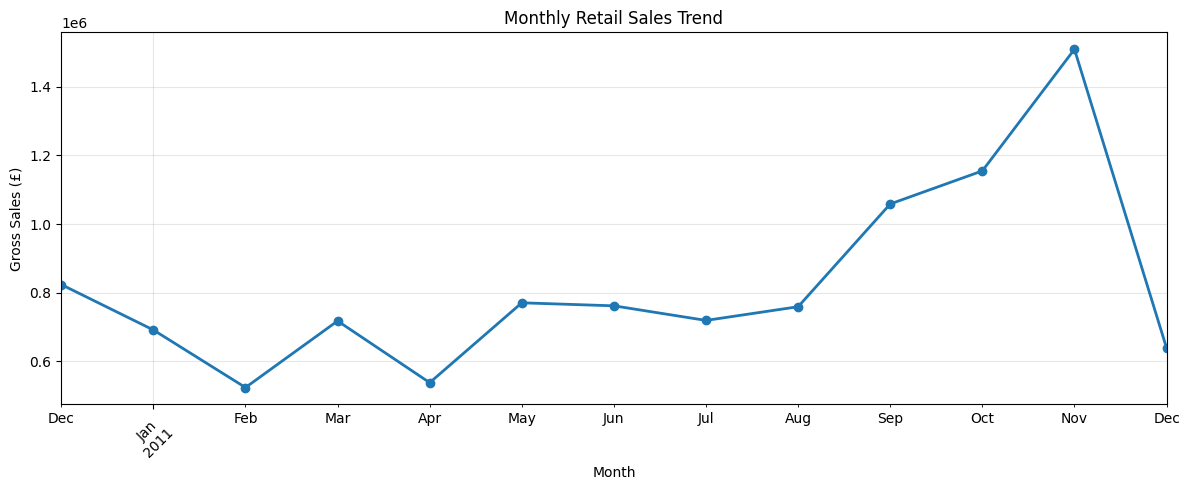

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

monthly_sales.plot(
    kind="line",
    marker="o",
    linewidth=2
)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Gross Sales (£)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


In [13]:

best_month = monthly_sales.idxmax()
worst_month = monthly_sales.idxmin()

print("Highest sales month:", best_month)
print(f"Sales: £{monthly_sales.max():,.2f}")

print("\nLowest sales month:", worst_month)
print(f"Sales: £{monthly_sales.min():,.2f}")


Highest sales month: 2011-11
Sales: £1,509,496.33

Lowest sales month: 2011-02
Sales: £523,631.89


In [14]:

# Focus on August to November 2011
holiday_trend = monthly_sales.loc[
    "2011-08":"2011-11"
]

print("Sales before the holiday season:")
print(holiday_trend)

# Calculate percentage changes
growth = holiday_trend.pct_change() * 100

print("\nMonthly growth rates (%):")
print(growth.round(2))

# Calculate overall growth
total_growth = (
    (holiday_trend.iloc[-1] /
     holiday_trend.iloc[0]) - 1
) * 100

print(f"\nAugust to November growth: {total_growth:.2f}%")


Sales before the holiday season:
YearMonth
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
Freq: M, Name: SalesAmount, dtype: float64

Monthly growth rates (%):
YearMonth
2011-08      NaN
2011-09    39.45
2011-10     9.11
2011-11    30.69
Freq: M, Name: SalesAmount, dtype: float64

August to November growth: 98.84%


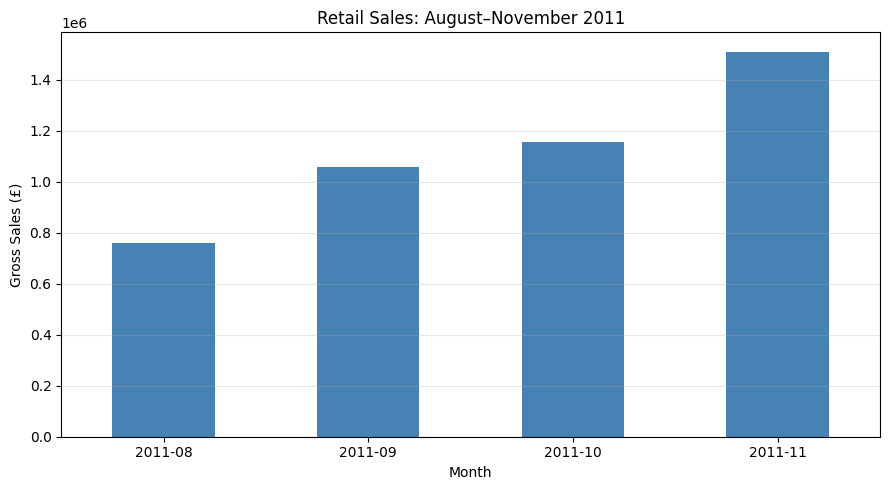

In [15]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

holiday_trend.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Retail Sales: August–November 2011")
plt.xlabel("Month")
plt.ylabel("Gross Sales (£)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()


In [16]:

# Calculate gross sales by product
top_products = (
    df_clean.groupby("Description")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products.round(2))


Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 78112.82
POSTAGE                                78101.88
RABBIT NIGHT LIGHT                     66964.99
Name: SalesAmount, dtype: float64


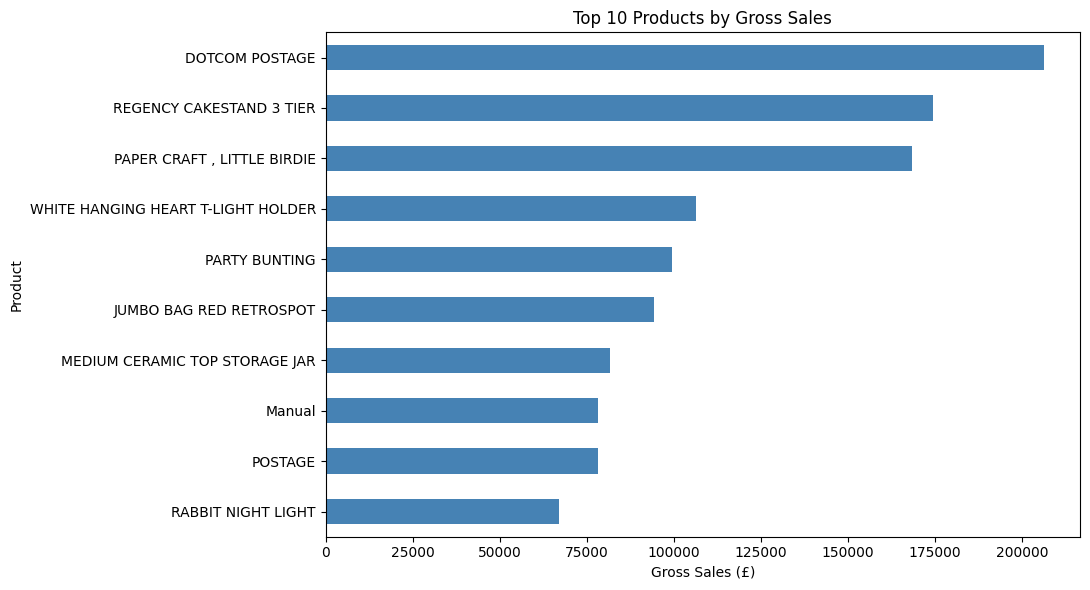

In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

top_products.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Products by Gross Sales")
plt.xlabel("Gross Sales (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [18]:

# Select August and November 2011
selected = df_clean[
    df_clean["YearMonth"].astype(str).isin(
        ["2011-08", "2011-11"]
    )
].copy()

# Aggregate sales by product and month
product_comparison = selected.pivot_table(
    index="StockCode",
    columns="YearMonth",
    values="SalesAmount",
    aggfunc="sum",
    fill_value=0
)

# Calculate change in sales
product_comparison["SalesChange"] = (
    product_comparison["2011-11"] -
    product_comparison["2011-08"]
)

# Show products with largest increases
print(
    product_comparison
    .sort_values("SalesChange", ascending=False)
    .head(10)
)


YearMonth   2011-08   2011-11  SalesChange
StockCode                                 
23084       3533.57  34556.72     31023.15
22086       1334.94  28985.04     27650.10
DOT        13400.52  36905.40     23504.88
22910       1224.17  12944.49     11720.32
23355        593.52  11824.42     11230.90
22197       4133.35  14195.60     10062.25
22114        368.94  10291.14      9922.20
23344       1191.54  11094.18      9902.64
84347        303.03   9633.54      9330.51
79321       2260.33  11485.77      9225.44


In [19]:

# Products with the largest sales increases
top_growth_codes = (
    product_comparison
    .sort_values("SalesChange", ascending=False)
    .head(10)
    .index
)

# Match codes to descriptions
product_names = (
    df_clean[
        df_clean["StockCode"].isin(top_growth_codes)
    ]
    .groupby("StockCode")["Description"]
    .agg(lambda x: x.mode().iloc[0])
)

# Add product names to our results
growth_results = (
    product_comparison
    .loc[top_growth_codes]
    .copy()
)

growth_results["ProductName"] = product_names

print(
    growth_results[
        ["ProductName", "SalesChange"]
    ].round(2)
)


YearMonth                          ProductName  SalesChange
StockCode                                                  
23084                       RABBIT NIGHT LIGHT     31023.15
22086          PAPER CHAIN KIT 50'S CHRISTMAS      27650.10
DOT                             DOTCOM POSTAGE     23504.88
22910        PAPER CHAIN KIT VINTAGE CHRISTMAS     11720.32
23355               HOT WATER BOTTLE KEEP CALM     11230.90
22197                           POPCORN HOLDER     10062.25
22114        HOT WATER BOTTLE TEA AND SYMPATHY      9922.20
23344                JUMBO BAG 50'S CHRISTMAS       9902.64
84347      ROTATING SILVER ANGELS T-LIGHT HLDR      9330.51
79321                            CHILLI LIGHTS      9225.44


In [20]:

# Known non-merchandise stock codes
non_merchandise_codes = [
    "DOT",    # Dotcom postage
    "POST",   # Postage
    "M",      # Manual
    "D",      # Discount
    "C2",     # Carriage
    "BANK CHARGES"
]

# Create a separate merchandise dataset
df_products = df_clean[
    ~df_clean["StockCode"]
    .astype(str)
    .isin(non_merchandise_codes)
].copy()

# Recalculate top products
top_merchandise = (
    df_products.groupby("Description")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_merchandise.round(2))


Description
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66964.99
PAPER CHAIN KIT 50'S CHRISTMAS         64952.29
ASSORTED COLOUR BIRD ORNAMENT          59094.93
CHILLI LIGHTS                          54117.76
Name: SalesAmount, dtype: float64


In [21]:

birdie = df_clean[
    df_clean["Description"]
    .str.contains("LITTLE BIRDIE", case=False, na=False)
]

print(
    birdie[
        ["InvoiceNo", "Quantity", "UnitPrice",
         "SalesAmount", "InvoiceDate"]
    ].sort_values(
        "SalesAmount", ascending=False
    ).head(10)
)

print("\nUnique orders:", birdie["InvoiceNo"].nunique())
print("Total units:", birdie["Quantity"].sum())


       InvoiceNo  Quantity  UnitPrice  SalesAmount         InvoiceDate
540421    581483     80995       2.08     168469.6 2011-12-09 09:15:00

Unique orders: 1
Total units: 80995


In [22]:

# Investigate the original invoice
invoice = df[
    df["InvoiceNo"].astype(str).str.contains("581483")
]

print(invoice[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "CustomerID"]
])

# Search for matching negative-quantity records
returns = df[
    (df["StockCode"] == "23843") &
    (df["Quantity"] < 0)
]

print("\nPotential returns:")
print(returns[
    ["InvoiceNo", "Quantity", "InvoiceDate"]
])


       InvoiceNo StockCode                  Description  Quantity  UnitPrice  \
540421    581483     23843  PAPER CRAFT , LITTLE BIRDIE     80995       2.08   

        CustomerID  
540421     16446.0  

Potential returns:
Empty DataFrame
Columns: [InvoiceNo, Quantity, InvoiceDate]
Index: []


In [23]:

# Exclude the specific invoice for sensitivity analysis
df_without_outlier = df_products[
    df_products["InvoiceNo"].astype(str) != "581483"
].copy()

# Recalculate product rankings
top_without_outlier = (
    df_without_outlier
    .groupby("Description")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_without_outlier.round(2))

# Compare total sales
original_sales = df_products["SalesAmount"].sum()
adjusted_sales = df_without_outlier["SalesAmount"].sum()

impact = (original_sales - adjusted_sales) / original_sales * 100

print(f"\nImpact on merchandise gross sales: {impact:.2f}%")


Description
REGENCY CAKESTAND 3 TIER              174484.74
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66964.99
PAPER CHAIN KIT 50'S CHRISTMAS         64952.29
ASSORTED COLOUR BIRD ORNAMENT          59094.93
CHILLI LIGHTS                          54117.76
SPOTTY BUNTING                         42548.13
Name: SalesAmount, dtype: float64

Impact on merchandise gross sales: 1.64%


In [24]:

# Select August and November merchandise sales
seasonal_data = df_products[
    df_products["YearMonth"].astype(str).isin(
        ["2011-08", "2011-11"]
    )
].copy()

# Identify products containing CHRISTMAS
seasonal_data["IsChristmas"] = (
    seasonal_data["Description"]
    .str.contains("CHRISTMAS", case=False, na=False)
)

# Compare sales by month and product type
christmas_sales = seasonal_data.groupby(
    ["YearMonth", "IsChristmas"],
    observed=True
)["SalesAmount"].sum().unstack(fill_value=0)

print(christmas_sales.round(2))


IsChristmas       False      True 
YearMonth                         
2011-08       712645.74   24021.48
2011-11      1299582.47  158163.06


In [25]:

christmas_sales.index = christmas_sales.index.astype(str)

aug = christmas_sales.loc["2011-08"]
nov = christmas_sales.loc["2011-11"]

christmas_growth = nov[True] - aug[True]
total_growth = nov.sum() - aug.sum()

contribution = christmas_growth / total_growth * 100

print(f"Christmas product sales increase: £{christmas_growth:,.2f}")
print(f"Total merchandise sales increase: £{total_growth:,.2f}")
print(f"Contribution to growth: {contribution:.2f}%")


Christmas product sales increase: £134,141.58
Total merchandise sales increase: £721,078.31
Contribution to growth: 18.60%


In [26]:

# Focus on August and November 2011
order_data = df_products[
    df_products["YearMonth"].astype(str).isin(
        ["2011-08", "2011-11"]
    )
].copy()

# Calculate sales and number of orders
monthly_kpis = order_data.groupby(
    "YearMonth"
).agg(
    GrossSales=("SalesAmount", "sum"),
    TotalOrders=("InvoiceNo", "nunique"),
    UnitsSold=("Quantity", "sum")
)

# Average order value
monthly_kpis["AvgOrderValue"] = (
    monthly_kpis["GrossSales"] /
    monthly_kpis["TotalOrders"]
)

print(monthly_kpis.round(2))


           GrossSales  TotalOrders  UnitsSold  AvgOrderValue
YearMonth                                                   
2011-08     736667.22         1340     421452         549.75
2011-11    1457745.53         2751     750082         529.90


In [27]:

aug = monthly_kpis.iloc[0]
nov = monthly_kpis.iloc[1]

for metric in [
    "GrossSales",
    "TotalOrders",
    "UnitsSold",
    "AvgOrderValue"
]:
    growth = (
        (nov[metric] - aug[metric]) /
        aug[metric]
    ) * 100

    print(f"{metric}: {growth:.2f}%")


GrossSales: 97.88%
TotalOrders: 105.30%
UnitsSold: 77.98%
AvgOrderValue: -3.61%


In [28]:

import sqlite3

# Create an in-memory database
conn = sqlite3.connect(":memory:")

# Prepare data for SQL
sql_df = df_products.copy()

# Convert dates to strings for SQLite
sql_df["InvoiceDate"] = (
    sql_df["InvoiceDate"].astype(str)
)

sql_df["YearMonth"] = (
    sql_df["YearMonth"].astype(str)
)

# Load data into a SQL table
sql_df.to_sql(
    "retail_sales",
    conn,
    if_exists="replace",
    index=False
)

print("Database created successfully!")


Database created successfully!


In [29]:

query = """
SELECT
    ROUND(SUM(SalesAmount), 2) AS TotalSales
FROM retail_sales;
"""

result = pd.read_sql_query(query, conn)

print(result)


    TotalSales
0  10297007.62


In [30]:

query = """
SELECT
    YearMonth,
    ROUND(SUM(SalesAmount), 2) AS MonthlySales
FROM retail_sales
GROUP BY YearMonth
ORDER BY YearMonth;
"""

monthly_sql = pd.read_sql_query(query, conn)

print(monthly_sql)


   YearMonth  MonthlySales
0    2010-12     791552.24
1    2011-01     671992.41
2    2011-02     508952.87
3    2011-03     691485.70
4    2011-04     516339.79
5    2011-05     741275.74
6    2011-06     738876.88
7    2011-07     689397.74
8    2011-08     736667.22
9    2011-09    1030500.36
10   2011-10    1106719.54
11   2011-11    1457745.53
12   2011-12     615501.60


In [31]:

query = """
SELECT
    YearMonth,
    COUNT(DISTINCT InvoiceNo) AS TotalOrders
FROM retail_sales
GROUP BY YearMonth
ORDER BY YearMonth;
"""

result = pd.read_sql_query(query, conn)
print(result)


   YearMonth  TotalOrders
0    2010-12         1551
1    2011-01         1081
2    2011-02         1093
3    2011-03         1441
4    2011-04         1236
5    2011-05         1668
6    2011-06         1525
7    2011-07         1452
8    2011-08         1340
9    2011-09         1818
10   2011-10         2006
11   2011-11         2751
12   2011-12          816


In [34]:




# Write SQL query inside triple quotes
query = """
SELECT
    Country,
    ROUND(SUM(SalesAmount), 2) AS TotalSales
FROM retail_sales
GROUP BY Country
ORDER BY TotalSales DESC
LIMIT 5;
"""

# Execute SQL query using Python
result = pd.read_sql_query(query, conn)

# Display results
display(result)


,Country,TotalSales
0,United Kingdom,8773136.22
1,Netherlands,283889.34
2,EIRE,271164.30
3,Germany,205569.89
4,France,184582.74


In [35]:

query = """
SELECT
    Country,
    ROUND(SUM(SalesAmount), 2) AS TotalSales,
    ROUND(
        SUM(SalesAmount) * 100.0 /
        (SELECT SUM(SalesAmount) FROM retail_sales),
        2
    ) AS SalesPercentage
FROM retail_sales
GROUP BY Country
ORDER BY TotalSales DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
display(result)


,Country,TotalSales,SalesPercentage
0,United Kingdom,8773136.22,85.20
1,Netherlands,283889.34,2.76
2,EIRE,271164.30,2.63
3,Germany,205569.89,2.00
4,France,184582.74,1.79
5,Australia,138171.31,1.34
6,Spain,55725.11,0.54
7,Switzerland,53087.90,0.52
8,Japan,37416.37,0.36
9,Belgium,36927.34,0.36
